# Aureas walkthrough

This notebook runs the Python version of Aureas on a folder of recordings:

1. The pipeline step by step on one recording: spectrogram, denoising, segmentation, features and LAMDA.
2. The full exploration of the folder and the results CSV (same columns as the MATLAB Excel).
3. The clusters: summary, representative elements, members and audio.
4. The effect of the dominant-frequency correction.
5. (Optional) Comparison with a CSV/Excel produced by the MATLAB application.

Set the paths in the next cell and run everything. A handful of recordings is enough.

In [ ]:
import os, sys
from pathlib import Path
# --- Paths ----------------------------------------------------------------------
AUDIO_DIR = Path(os.environ.get("AUREAS_AUDIO_DIR", "/Volumes/Seagate MJ/Datasets Aureas/Species Subset"))      # searched recursively
RESULTS_DIR = Path(os.environ.get("AUREAS_RESULTS_DIR", "results"))               # a new run folder is created inside
AUREAS_PY = Path(os.environ.get("AUREAS_PY", "/Volumes/Seagate MJ/Aureas Junio 2023-1/aureas-py"))

In [34]:
if (AUREAS_PY / "aureas").exists() and str(AUREAS_PY.resolve()) not in sys.path:
    sys.path.insert(0, str(AUREAS_PY.resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import Audio, display

import aureas
from aureas.io import list_audio, load_audio
from aureas.matlab_compat import spectrogram

pd.set_option("display.max_columns", 30)
print("aureas", aureas.__version__)
files = list_audio(AUDIO_DIR)
print(f"{len(files)} recordings:", *[f.name for f in files[:20]], sep="\n  ")

aureas 0.1.0
215 recordings:
  SMA03126_20210611_200000.wav
  SMA03247_20210605_200000.wav
  SMA03247_20210606_191000.wav
  SMA03247_20210606_200000.wav
  SMA03251_20210604_200000.wav
  SMA03251_20210605_194000.wav
  SMA03286_20210604_200000.wav
  SMA03286_20210608_200000.wav
  SMA03294_20210603_193000.wav
  SMA03326_20210611_183000.wav
  SMA03328_20210606_195000.wav
  SMA03328_20210606_200000.wav
  SMA03330_20210603_191000.wav
  SMA03330_20210609_192000.wav
  SMA03393_20210602_190000.wav
  SMA03393_20210602_193000.wav
  SMA03393_20210609_200000.wav
  SMA03406_20210601_191000.wav
  SMA03406_20210601_200000.wav
  SMA03406_20210608_194000.wav


## 1. The pipeline step by step on one recording

Each stage is an independent function:

`spectrogram` → `denoise` → `detect_events` → `extract_features` → `MinMaxScaler` → `LAMDA`

SMA03327_20210322_170000.wav: 60.0 s at 48000 Hz


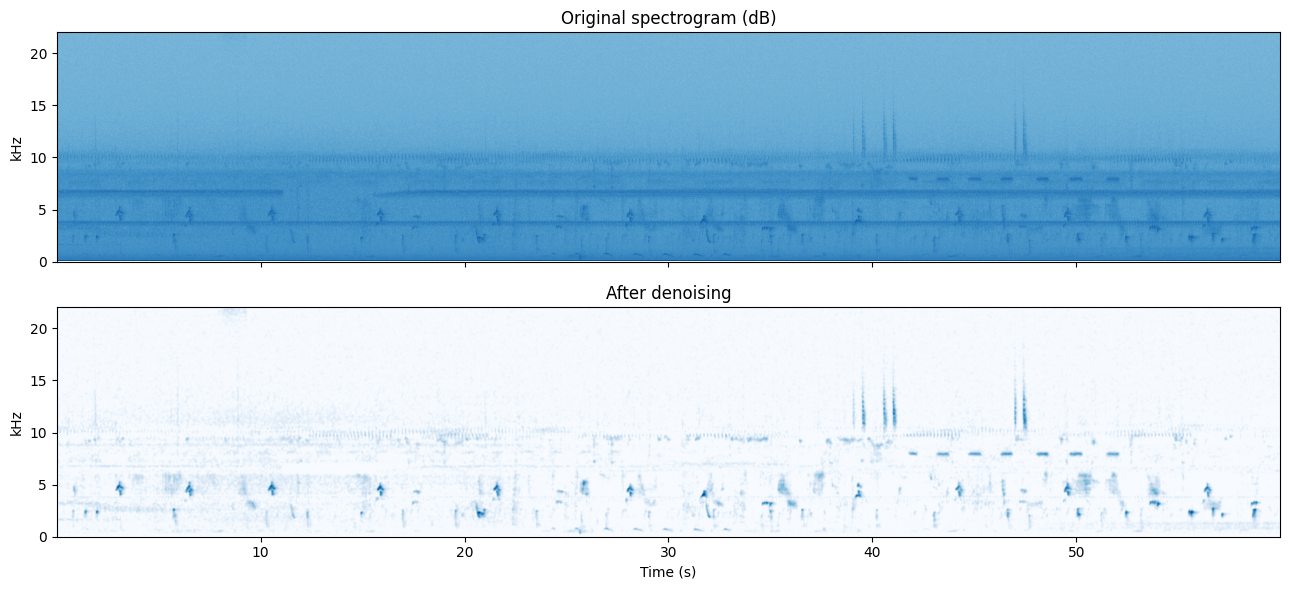

In [60]:
wav = files[200]
x, fs = load_audio(wav, channel=1)
print(f"{wav.name}: {len(x)/fs:.1f} s at {fs} Hz")

# Spectrogram with the MATLAB parameters: Hamming 1024, 50 % overlap, nfft 2048
S, f, t, P = spectrogram(x, fs, nwin=1024, noverlap=512, nfft=2048)

# Denoising: dB -> Gaussian filter (sigma 3) -> subtraction of the per-band mode
I = aureas.denoise(P)

fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].imshow(10*np.log10(P[1:1025] + 1e-20), origin="lower", aspect="auto", cmap="Blues",
             extent=[t[0], t[-1], f[1]/1000, f[1024]/1000])
ax[0].set_title("Original spectrogram (dB)"); ax[0].set_ylabel("kHz")
ax[1].imshow(I, origin="lower", aspect="auto", cmap="Blues", extent=[t[0], t[-1], f[1]/1000, f[1024]/1000])
ax[1].set_title("After denoising"); ax[1].set_ylabel("kHz"); ax[1].set_xlabel("Time (s)")
for a in ax: a.set_ylim(0, 22)
plt.tight_layout(); plt.show()

119 events detected


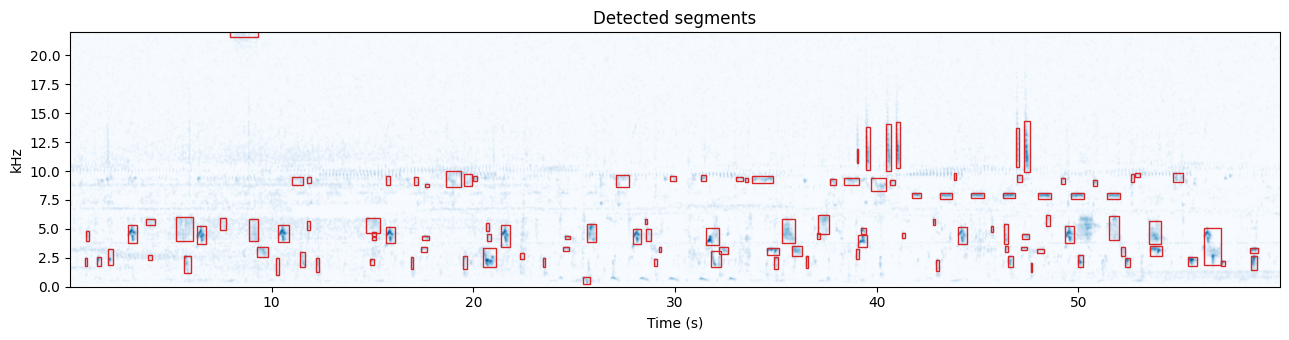

In [61]:
# Segmentation: Otsu x1.1 + opening 9x7 + closing 6x6 + geometric filters
events = aureas.detect_events(I, f, t)
print(f"{len(events)} events detected")

fig, ax = plt.subplots(figsize=(13, 3.5))
ax.imshow(I, origin="lower", aspect="auto", cmap="Blues", extent=[t[0], t[-1], f[1]/1000, f[1024]/1000])
for e in events.itertuples():
    ax.add_patch(Rectangle((e.t_start, e.f_low/1000), e.t_end-e.t_start, (e.f_high-e.f_low)/1000,
                           fill=False, ec="#d62728", lw=1))
ax.set_ylim(0, 22); ax.set_xlabel("Time (s)"); ax.set_ylabel("kHz"); ax.set_title("Detected segments")
plt.tight_layout(); plt.show()

In [37]:
# Features: Fdom, Fmin, Fmax + 23 coefficients (4x4 LFCC without c0, delta and delta-delta)
table, X, n_dropped = aureas.extract_features(S, f, t, fs, events)
print(f"{len(table)} segments with features, {n_dropped} dropped (too short or narrow for the LFCC)")
print("Feature matrix:", X.shape)
pd.DataFrame(X[:5], columns=aureas.feature_names()).round(3)

213 segments with features, 6 dropped (too short or narrow for the LFCC)
Feature matrix: (213, 26)


,fdom,fmin,fmax,lfcc_c1_t0,lfcc_c2_t0,lfcc_c3_t0,lfcc_c0_t1,lfcc_c1_t1,lfcc_c2_t1,lfcc_c3_t1,lfcc_c0_t2,lfcc_c1_t2,lfcc_c2_t2,lfcc_c3_t2,lfcc_c0_t3,lfcc_c1_t3,lfcc_c2_t3,lfcc_c3_t3,d_c0,d_c1,d_c2,d_c3,dd_c0,dd_c1,dd_c2,dd_c3
0,8882.812,8390.625,9914.062,-0.154,1.077,0.272,22.196,-0.113,1.130,0.075,22.576,-0.218,1.013,0.100,22.970,-0.207,1.122,0.223,0.367,-0.018,0.015,-0.016,0.035,-0.015,0.028,0.160
1,4101.562,3984.375,6234.375,-9.376,0.537,0.490,10.101,-10.163,0.826,0.852,8.793,-9.145,0.167,0.488,8.691,-10.350,0.809,0.545,-0.319,-0.325,0.091,0.018,-0.277,-0.210,0.176,-0.152
2,7031.250,6539.062,7148.438,2.721,-1.382,-1.320,17.499,2.808,-2.126,-1.751,18.898,2.823,-1.766,-0.514,21.663,2.240,-2.602,-0.159,0.242,-0.160,-0.407,0.387,3.102,-0.335,-0.046,0.393
3,4125.000,3960.938,7078.125,-4.302,5.703,3.101,16.063,-6.040,7.156,2.848,19.665,-6.739,6.832,3.109,18.682,-6.466,6.871,3.213,2.794,-0.721,0.389,0.038,-3.374,1.006,-0.707,0.178
4,5320.312,5226.562,6351.562,-0.534,1.600,-0.795,-4.008,-1.001,1.688,-0.530,-3.425,-0.931,1.130,-0.628,-7.969,-0.748,0.760,0.135,0.312,-0.072,-0.280,0.310,-4.720,0.325,-0.229,0.249


In [38]:
# Min-max scaling to [0, 1] and LAMDA 3pi, on this recording only
Z = aureas.MinMaxScaler().fit_transform(X)
labels, G, prototypes = aureas.LAMDA(nic_init="mean").fit_predict(Z)
print(f"{labels.max()} clusters + NIC; segments per class (0 = NIC):")
print(pd.Series(labels).value_counts().sort_index().to_dict())

8 clusters + NIC; segments per class (0 = NIC):
{0: 22, 1: 63, 2: 11, 3: 13, 4: 11, 5: 44, 6: 18, 7: 13, 8: 18}


## 2. Full exploration of the folder

`aureas.explore` does all of the above for every recording and saves a run folder with:

- `Classification_<date>.csv`: **the same columns as the MATLAB Excel** (File … Class, Membership) plus extra columns.
- `Full_results.csv`, `Normalized_features.csv`, `Memberships.csv`, `Run_summary.csv`.
- `clusters.csv`, `arrays.npz`, `config.yaml`, `run.yaml`.

In [39]:
res = aureas.explore(AUDIO_DIR, results_dir=RESULTS_DIR)
m = res.meta
print(f"{m['n_segments']} segments from {m['n_files']} recordings -> {m['n_clusters']} clusters + NIC "
      f"({m['n_dropped']} dropped). CV index: {m['cv_index']:.3f}")
print("Results in:", res.path)
res.table().head(10)

40294 segments from 161 recordings -> 178 clusters + NIC (2052 dropped). CV index: 0.001
Results in: /Volumes/Seagate MJ/Aureas Junio 2023-1/aureas-py/examples/results/2026-10-18_18-26-20_explore_Species_Subset


,File,Month,Day,Hour,Minute,Start,End,Length,Fdom,FminVoc,FmaxVoc,Fmin,Fmax,Class,Membership,SegmentID,Year,Second,Datetime,Site,Path,SampleRate,MembershipAssigned,IsRepresentative
0,SMA03126_20210611_200000.wav,6,11,20,0,0.170667,0.789333,0.618667,3726.5625,2460.9375,3843.7500,23.4375,24000.0,1,0.954182,0,2021,0,2021-06-11 20:00:00,SMA03126,/Volumes/Seagate MJ/Datasets Aureas/Species Su...,48000,0.851595,True
1,SMA03126_20210611_200000.wav,6,11,20,0,0.234667,0.437333,0.202667,5156.2500,4804.6875,5273.4375,23.4375,24000.0,67,0.892277,1,2021,0,2021-06-11 20:00:00,SMA03126,/Volumes/Seagate MJ/Datasets Aureas/Species Su...,48000,0.892277,False
2,SMA03126_20210611_200000.wav,6,11,20,0,0.512000,0.672000,0.160000,6867.1875,6679.6875,7031.2500,23.4375,24000.0,1,0.755145,2,2021,0,2021-06-11 20:00:00,SMA03126,/Volumes/Seagate MJ/Datasets Aureas/Species Su...,48000,0.682918,False
3,SMA03126_20210611_200000.wav,6,11,20,0,0.586667,0.714667,0.128000,4382.8125,4218.7500,4687.5000,23.4375,24000.0,54,0.904461,3,2021,0,2021-06-11 20:00:00,SMA03126,/Volumes/Seagate MJ/Datasets Aureas/Species Su...,48000,0.904461,False
4,SMA03126_20210611_200000.wav,6,11,20,0,0.960000,1.322667,0.362667,5156.2500,5156.2500,5882.8125,23.4375,24000.0,60,0.852148,4,2021,0,2021-06-11 20:00:00,SMA03126,/Volumes/Seagate MJ/Datasets Aureas/Species Su...,48000,0.852148,False
5,SMA03126_20210611_200000.wav,6,11,20,0,1.013333,1.333333,0.320000,4968.7500,4195.3125,4992.1875,23.4375,24000.0,98,0.869588,5,2021,0,2021-06-11 20:00:00,SMA03126,/Volumes/Seagate MJ/Datasets Aureas/Species Su...,48000,0.869588,False
6,SMA03126_20210611_200000.wav,6,11,20,0,1.184000,1.365333,0.181333,2648.4375,2109.3750,2765.6250,23.4375,24000.0,72,0.970144,6,2021,0,2021-06-11 20:00:00,SMA03126,/Volumes/Seagate MJ/Datasets Aureas/Species Su...,48000,0.970144,False
7,SMA03126_20210611_200000.wav,6,11,20,0,1.440000,1.546667,0.106667,4359.3750,4242.1875,4687.5000,23.4375,24000.0,34,0.900923,7,2021,0,2021-06-11 20:00:00,SMA03126,/Volumes/Seagate MJ/Datasets Aureas/Species Su...,48000,0.900923,False
8,SMA03126_20210611_200000.wav,6,11,20,0,1.568000,2.112000,0.544000,3726.5625,2648.4375,4007.8125,23.4375,24000.0,2,0.959050,8,2021,0,2021-06-11 20:00:00,SMA03126,/Volumes/Seagate MJ/Datasets Aureas/Species Su...,48000,0.959050,False
9,SMA03126_20210611_200000.wav,6,11,20,0,2.261333,2.656000,0.394667,4195.3125,4195.3125,5882.8125,23.4375,24000.0,113,0.886349,9,2021,0,2021-06-11 20:00:00,SMA03126,/Volumes/Seagate MJ/Datasets Aureas/Species Su...,48000,0.886349,False


In [40]:
# Summary per cluster (Class 1 = NIC, as in MATLAB)
cols = ["Class", "n_segments", "pct_of_all", "confident_pct", "membership_median",
        "fdom_median", "fmin_median", "fmax_median", "length_median", "n_recordings", "closest_class"]
res.clusters[cols].sort_values("n_segments", ascending=False).round(2).head(15)

,Class,n_segments,pct_of_all,confident_pct,membership_median,fdom_median,fmin_median,fmax_median,length_median,n_recordings,closest_class
0,1,11426,28.36,0.00,0.54,9960.94,9445.31,11085.94,0.22,157,160
4,5,2572,6.38,100.00,1.00,914.06,632.81,1593.75,0.28,128,29
7,8,1850,4.59,92.22,0.99,21234.38,20835.94,22031.25,0.18,85,21
71,72,1510,3.75,100.00,0.98,2226.56,1664.06,2507.81,0.18,105,56
5,6,1193,2.96,99.08,0.97,2671.88,1804.69,2835.94,0.25,116,45
20,21,1149,2.85,15.93,0.85,15703.12,15468.75,16078.12,0.18,68,83
55,56,972,2.41,100.00,0.98,1945.31,1523.44,2437.50,0.20,118,96
28,29,808,2.01,100.00,0.98,2414.06,1710.94,2648.44,0.18,65,96
95,96,743,1.84,100.00,0.98,2367.19,1687.50,2671.88,0.17,93,56
8,9,739,1.83,99.05,0.96,4031.25,3726.56,5203.12,0.38,58,43


## 3. Clusters: representative elements and members

The representative element of a cluster is the member with the highest global adequacy degree (GAD), as in `Metodologia.m`.

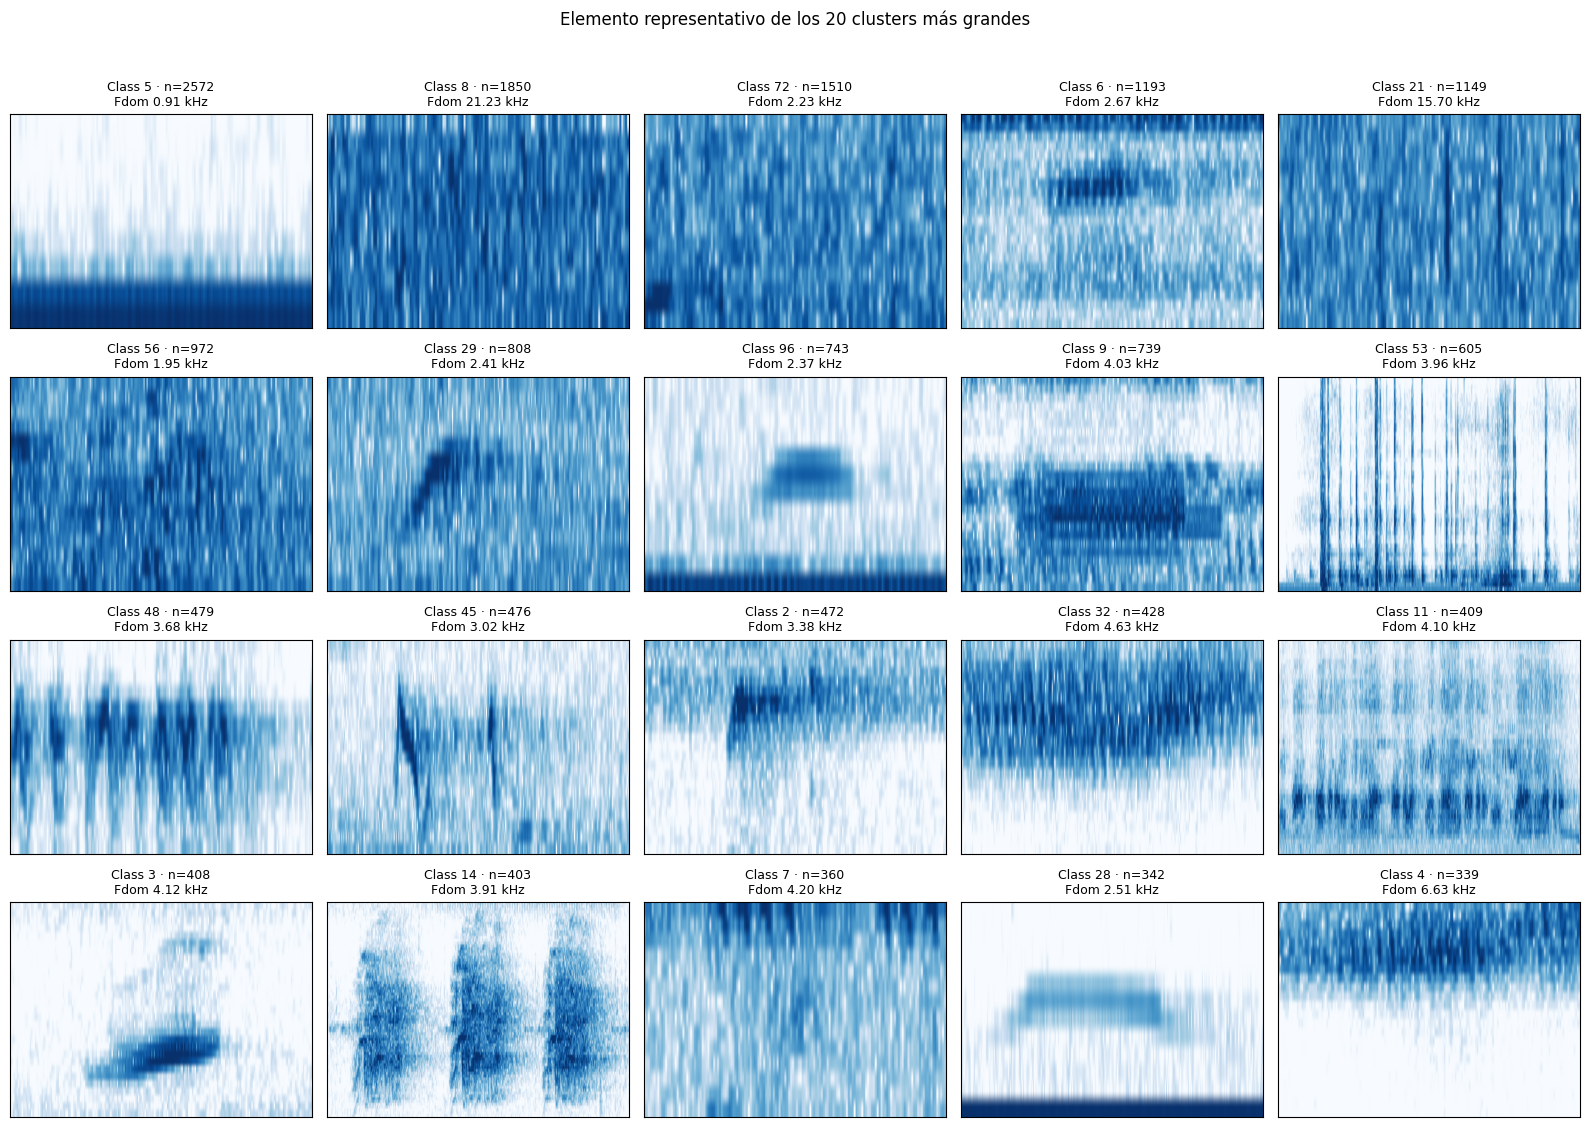

In [51]:
def plot_segment(ax, row, ctx=0.15, fpad=400, title=None):
    a, b = max(0, row.Start - ctx), row.End + ctx
    y, sr = load_audio(row.Path, 1, a, b)
    nwin = 512
    S_, f_, t_, P_ = spectrogram(y, sr, nwin, 384, nwin)
    lo, hi = max(0, row.FminVoc - fpad), min(sr/2, row.FmaxVoc + fpad)
    r = (f_ >= lo) & (f_ <= hi)
    img = 10*np.log10(P_[r] + 1e-20); vmax = np.percentile(img, 99.5)
    ax.imshow(img, origin="lower", aspect="auto", cmap="Blues", vmin=vmax-45, vmax=vmax,
              extent=[a, a + len(y)/sr, lo/1000, hi/1000])
    ax.set_xticks([]); ax.set_yticks([])
    if title: ax.set_title(title, fontsize=9)

seg = res.segments
top = res.clusters[res.clusters.Class > 1].sort_values("n_segments", ascending=False).head(20)
fig, axes = plt.subplots(4, 5, figsize=(16, 11))
for ax, c in zip(axes.ravel(), top.itertuples()):
    r = seg.loc[int(c.representative)]
    plot_segment(ax, r, title=f"Class {c.Class} · n={c.n_segments}\nFdom {c.fdom_median/1000:.2f} kHz")
fig.suptitle("Elemento representativo de los 20 clusters más grandes", y=1.02)
plt.tight_layout(); plt.show()

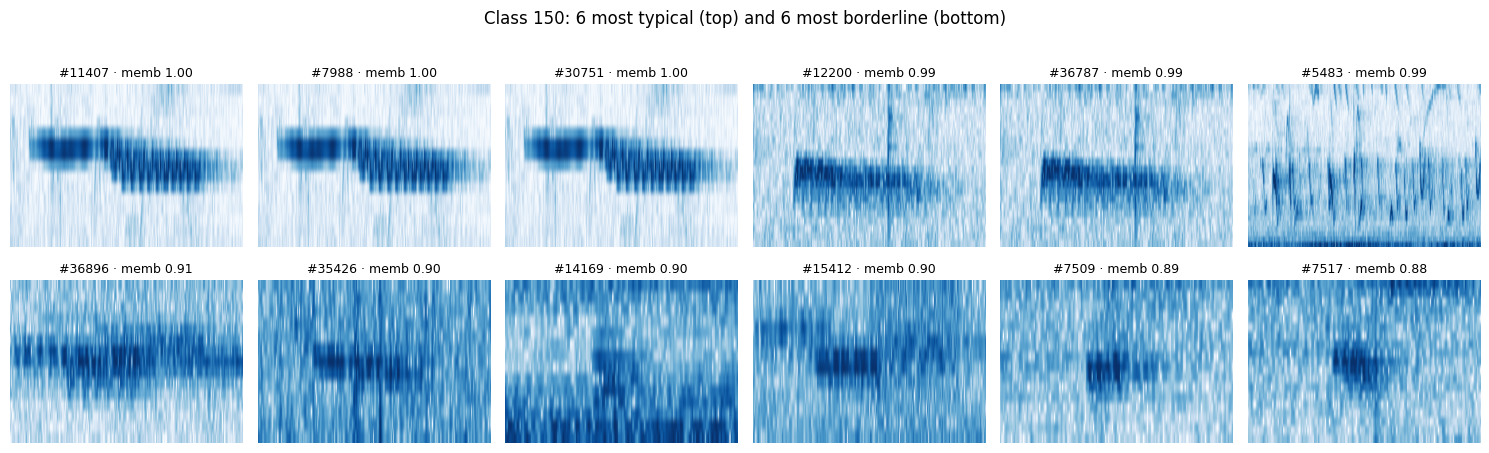

In [71]:
# Members of one cluster, from most typical to most borderline (change CLASS to see another one)
CLASS = 150
mem = res.members(CLASS, "typical")
sel = pd.concat([mem.head(6), mem.tail(6)])
fig, axes = plt.subplots(2, 6, figsize=(15, 4.4))
for ax in axes.ravel(): ax.set_axis_off()
for ax, r in zip(axes.ravel(), sel.itertuples()):
    plot_segment(ax, r, title=f"#{r.SegmentID} · memb {r.MembershipAssigned:.2f}")
fig.suptitle(f"Class {CLASS}: 6 most typical (top) and 6 most borderline (bottom)", y=1.02)
plt.tight_layout(); plt.show()

In [72]:
# Listen to the representative element of that cluster (0.5 s before and after)
r = seg.loc[int(res.clusters.set_index("Class").loc[CLASS, "representative"])]
y, sr = load_audio(r.Path, 1, max(0, r.Start - 0.5), r.End + 0.5)
print(f"{r.File}  {r.Start:.2f}-{r.End:.2f} s  Fdom {r.Fdom:.0f} Hz")
display(Audio(y, rate=sr))

SMA03210_20210320_054000.wav  31.35-32.68 s  Fdom 2109 Hz


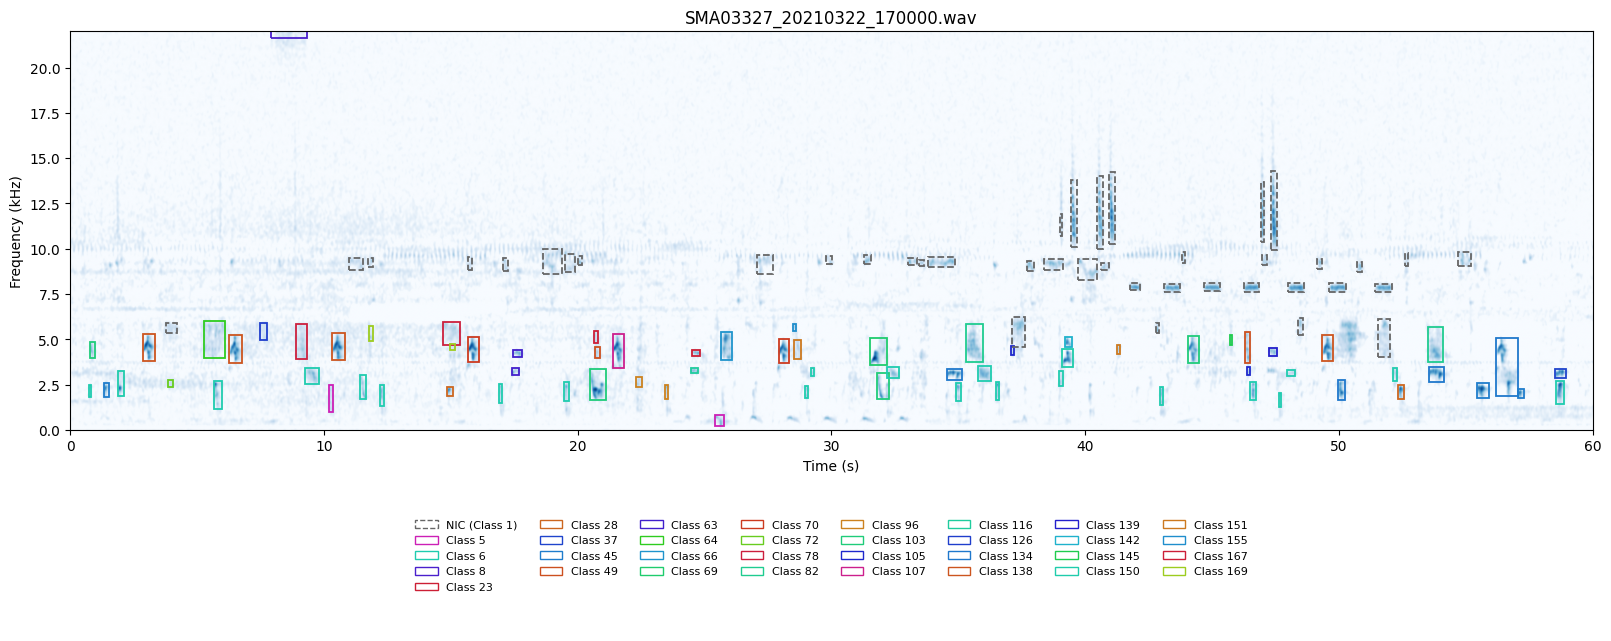

In [74]:
from matplotlib.colors import hsv_to_rgb
from matplotlib.patches import Patch

def plot_segmentos_por_clase(res, archivo, mostrar_numeros=False):
    archivo = Path(archivo).resolve()
    rutas = res.segments["Path"].map(lambda p: str(Path(p).resolve()))
    segmentos_audio = res.segments.loc[rutas == str(archivo)]
    if segmentos_audio.empty:
        raise ValueError(f"No hay segmentos clasificados de {archivo.name} en esta corrida.")

    
    sp, dn = res.config["spectrogram"], res.config["denoising"]
    audio, sr = load_audio(archivo, channel=res.config["channel"])
    _, frecuencias, tiempos, potencia = spectrogram(
        audio, sr, nwin=sp["nwin"], noverlap=sp["noverlap"], nfft=sp["nfft"])
    imagen = aureas.denoise(potencia, nwin=sp["nwin"],
                           sigma=dn["gaussian_sigma"], smooth_span=dn["mode_smooth_span"])

    
    clases = sorted(int(c) for c in segmentos_audio["Class"].unique())
    colores = {
        c: ("#666666" if c == 1 else hsv_to_rgb([((c - 2) * 0.61803398875) % 1, 0.85, 0.80]))
        for c in clases
    }
    ncols = min(8, len(clases))
    filas_leyenda = int(np.ceil(len(clases) / ncols))
    fig = plt.figure(figsize=(16, 4.8 + 0.3 * filas_leyenda), layout="constrained")
    grid = fig.add_gridspec(2, 1, height_ratios=[4, max(0.4, 0.3 * filas_leyenda)])
    ax = fig.add_subplot(grid[0])
    ax_leyenda = fig.add_subplot(grid[1])
    ax_leyenda.axis("off")
    ax.imshow(imagen, origin="lower", aspect="auto", cmap="Blues",
              extent=[tiempos[0], tiempos[-1], frecuencias[1] / 1000,
                      frecuencias[imagen.shape[0]] / 1000])
    for segmento in segmentos_audio.itertuples():
        clase = int(segmento.Class)
        ax.add_patch(Rectangle(
            (segmento.Start, segmento.FminVoc / 1000),
            segmento.End - segmento.Start,
            (segmento.FmaxVoc - segmento.FminVoc) / 1000,
            fill=False, edgecolor=colores[clase], linewidth=1.3,
            linestyle="--" if clase == 1 else "-"))
        if mostrar_numeros:
            ax.text(segmento.Start, segmento.FmaxVoc / 1000, str(clase),
                    color=colores[clase], fontsize=7, va="bottom", clip_on=True)
    ax.set(xlim=(0, len(audio) / sr), ylim=(0, min(22, sr / 2000)),
           xlabel="Time (s)", ylabel="Frequency (kHz)",
           title=f"{archivo.name}")
    leyenda = [Patch(facecolor="none", edgecolor=colores[c],
                     linestyle="--" if c == 1 else "-",
                     label="NIC (Class 1)" if c == 1 else f"Class {c}") for c in clases]
    ax_leyenda.legend(handles=leyenda, loc="center", ncol=ncols, frameon=False, fontsize=8)
    return fig, ax


fig_clases, ax_clases = plot_segmentos_por_clase(res, wav, mostrar_numeros=False)
plt.show()


## Next steps

- Browse the run (clusters, representatives, recordings with coloured segments, table, audio):
  `aureas dashboard "<run folder>"` in a terminal (the folder is `res.path`), or open `results_viewer.ipynb`.
- Save a cluster as a sonotype and look for it in other recordings:

```python
lib = aureas.Library(RESULTS_DIR / "sonotypes.json")
lib.add_from_results(res, "Species name", cls=CLASS); lib.save()
aureas.search("/path/to/other/recordings", lib, ["Species name"])
```

In [ ]:
print("Run saved in:", res.path)
print("CSV:", res.meta["csv"])